# Плей-офф НХЛ 2026

Решения пунктов 1-22. Подробности - в `report.txt`. Путь к Excel меняется в ячейке ниже; затем запускаем тетрадь сверху вниз.

### Библиотеки

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_colwidth", 130)

### Файл с данными

Меняем путь только здесь.

In [2]:
# Файл с данными
file_path = r"NHL-playoffs-2026.xlsx"
events = pd.read_excel(file_path, index_col=0)
input_shape = events.shape
print("Размер таблицы:", input_shape)

Размер таблицы: (29710, 38)


## 1. Данные

Первую колонку Excel читаем как сохранённый индекс.

In [3]:
display(events.iloc[:10, [2, 3, 4, 9, 12]])
print("Пропусков в Game ID:", events["Game ID"].isna().sum())

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Пропусков в Game ID: 0


Получилось 29 710 строк и 38 столбцов, как в задании.

## 2. Итоги матчей

Берём итоговый счёт из `game-end`, число овертаймов - из периода.

In [4]:
def format_outcome(period):
    overtimes = period - 3
    if overtimes == 0:
        return "Final"
    if overtimes == 1:
        return "Final/OT"
    return f"Final/{overtimes}OT"

games = events.loc[
    events["Play Type"] == "game-end",
    [
        "Game ID",
        "Date",
        "Away Team",
        "Home Team",
        "Cumulated Away Score",
        "Cumulated Home Score",
        "Period",
    ],
].copy()

games = games.set_index("Game ID").sort_index()
games = games.rename(columns={
    "Cumulated Away Score": "Away Score",
    "Cumulated Home Score": "Home Score",
})

games["Outcome"] = games["Period"].apply(format_outcome)
games = games.drop(columns="Period")

print("Матчей:", len(games))
print("Столбцы:", list(games.columns))
display(games.head())
display(games.tail())
display(games["Outcome"].value_counts())

Матчей: 82
Столбцы: ['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome']


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Из 82 матчей 60 закончились в основное время, 18 - в первом OT, 4 - во втором.

## 3. Описание матча

Функция возвращает строку; хозяева и их счёт идут первыми.

In [5]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {game['Date']})"
    )

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Сколько голов за матч

Суммируем голы обеих команд.

In [6]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
score_stats = games["Total Score"].describe()
display(score_stats.round(3))

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

Среднее - 5,93, медиана - 6 голов. Минимум - 1, максимум - 15.

## 5. Распределение голов

По X - сумма голов, по Y - число матчей.

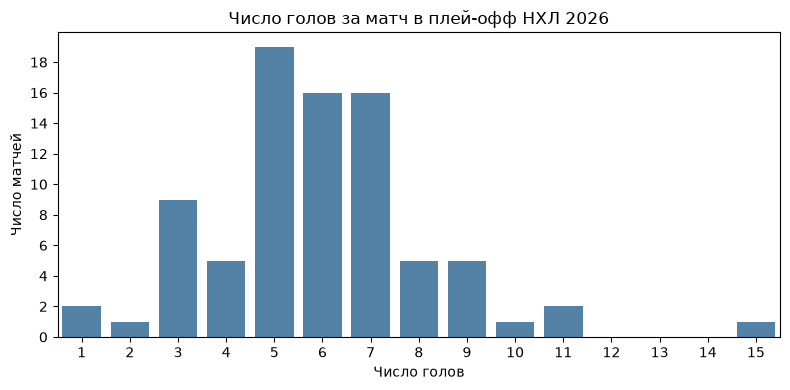

In [7]:
goal_values = range(games["Total Score"].min(), games["Total Score"].max() + 1)
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=games, x="Total Score", order=goal_values, color="steelblue")
plt.xlabel("Число голов")
plt.ylabel("Число матчей")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.title("Число голов за матч в плей-офф НХЛ 2026")
plt.tight_layout()
plt.show()

Чаще всего было 5 голов. В 62% матчей забили 5-7 голов; справа есть хвост до 15.

## 6. Самые результативные и нерезультативные игры

Выводим все матчи с минимумом и максимумом голов.

In [8]:
min_total = games["Total Score"].min()
max_total = games["Total Score"].max()

least_ids = games.index[games["Total Score"] == min_total]
most_ids = games.index[games["Total Score"] == max_total]

least_games = []
for gameId in least_ids:
    least_games.append(gameInfo(gameId))

most_games = []
for gameId in most_ids:
    most_games.append(gameInfo(gameId))

print(least_games)
print(most_games)

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Два минимума - по 1 голу. Максимум - Colorado - Minnesota, 9:6.

## 7. Сколько игроков участвовало

Считаем разные имена за весь матч, включая вратарей и удаляя пропуски.

In [9]:
player_columns = []
for team in ["Away", "Home"]:
    for number in range(1, 7):
        player_columns.append(f"{team} Team's Player on the Ice #{number}")
    player_columns.append(f"{team} Team's Goalie")

# Без повторов
player_counts = {}
for gameId, game_events in events.groupby("Game ID"):
    players = set()
    for column in player_columns:
        for player in game_events[column].dropna():
            players.add(player)
    player_counts[gameId] = len(players)

games["Player Count"] = pd.Series(player_counts)
max_player_count = games["Player Count"].max()

most_player_games = games.loc[
    games["Player Count"] == max_player_count, ["Player Count"]
].copy()
most_player_games["Game Info"] = most_player_games.index.map(gameInfo)
most_player_games = most_player_games[["Game Info", "Player Count"]]

display(most_player_games)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


Максимум - **40**, по 20 у каждой команды. В примере 41, причина расхождения неизвестна; пропуск игроком не считаем. Повтор Away в условии понимаем как Away и Home.

## 8. Расстояние броска до ворот

Точные броски - `goal` и `shot-on-goal`, промахи - `missed-shot`. Считаем расстояние до ближайшей точки створа в футах.

In [10]:
def shot_length(event):
    x = event["X Coordinate on the Ice Rink"]
    y = event["Y Coordinate on the Ice Rink"]

    if event["Home Team's Defending Side"] == "left":
        goal_x = 89
    elif event["Home Team's Defending Side"] == "right":
        goal_x = -89
    else:
        raise ValueError("Неизвестная сторона защиты хозяев")

    if event["Team Making the Play"] == event["Away Team"]:
        goal_x = -goal_x
    elif event["Team Making the Play"] != event["Home Team"]:
        raise ValueError("Команда броска не совпадает с участниками матча")

    # Ближайшая точка ворот
    if y < -3:
        return ((x - goal_x) ** 2 + (y + 3) ** 2) ** 0.5
    if y <= 3:
        return abs(x - goal_x)
    return ((x - goal_x) ** 2 + (y - 3) ** 2) ** 0.5

shot_types = ["shot-on-goal", "goal", "missed-shot"]
shot_mask = events["Play Type"].isin(shot_types)
events.loc[shot_mask, "Shot Length"] = events.loc[shot_mask].apply(
    shot_length, axis=1
)

shot_lengths = events.loc[shot_mask, ["Game ID", "Play Type", "Shot Length"]]
print("Бросков:", len(shot_lengths))
print("Не посчитано расстояний:", shot_lengths["Shot Length"].isna().sum())
display(shot_lengths.head().round(3))
display(shot_lengths.tail().round(3))

Бросков: 7266
Не посчитано расстояний: 0


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924


,Game ID,Play Type,Shot Length
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926
29707,2025030416,shot-on-goal,49.041


Расстояния найдены для всех 7266 бросков, пропусков нет.

## 9. Точные броски и промахи

Сравниваем плотности с отдельной нормировкой каждой группы.

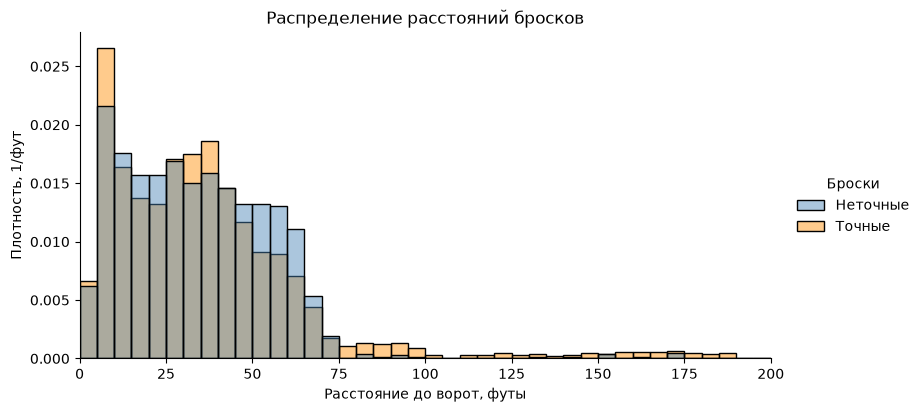

,count,mean,median
Shot,,,
Неточные,2643,34.014,32.249
Точные,4623,36.207,31.828


Shot
Неточные     23
Точные      160
Name: Дальше 100 футов, dtype: int64

In [11]:
shots = events.loc[shot_mask].copy()
shots["Shot"] = "Точные"
shots.loc[shots["Play Type"] == "missed-shot", "Shot"] = "Неточные"

bin_edges = range(0, 201, 5)
shot_plot = sns.displot(
    data=shots,
    x="Shot Length",
    hue="Shot",
    hue_order=["Неточные", "Точные"],
    palette={"Неточные": "steelblue", "Точные": "darkorange"},
    bins=bin_edges,
    stat="density",
    common_norm=False,
    common_bins=True,
    alpha=0.45,
    height=4,
    aspect=2,
)
shot_plot.set_axis_labels("Расстояние до ворот, футы", "Плотность, 1/фут")
shot_plot.set(xlim=(0, 200))
shot_plot.ax.set_title("Распределение расстояний бросков")
shot_plot.legend.set_title("Броски")
plt.show()

display(shots.groupby("Shot")["Shot Length"].agg(["count", "mean", "median"]).round(3))
long_shots = shots.loc[shots["Shot Length"] > 100].groupby("Shot").size()
display(long_shots.rename("Дальше 100 футов"))

Медианы близки к 32 футам, но у точных бросков длиннее дальний хвост. Возможно, это выносы и дальние броски из своей зоны, в том числе по пустым воротам; точная причина неизвестна.

## 10. Доля попаданий в створ за матч

Делим точные броски на точные плюс промахи, без блокировок.

In [12]:
shots["On Goal"] = shots["Play Type"].isin(["shot-on-goal", "goal"])
numshots = shots.groupby(["Game ID", "Team Making the Play"])["On Goal"].agg(
    ["sum", "count"]
)
numshots = numshots.rename(columns={
    "sum": "Shots on Goal",
    "count": "Unblocked Shots",
})
numshots["Share of Shots on Goal"] = (
    numshots["Shots on Goal"] / numshots["Unblocked Shots"]
)
print("Пар матч-команда:", len(numshots))
display(numshots.head(6).round(3))
display(numshots.tail(4).round(3))
print("В створ:", numshots["Shots on Goal"].sum())
print("Незаблокированных:", numshots["Unblocked Shots"].sum())
print("Диапазон долей:", numshots["Share of Shots on Goal"].min(), numshots["Share of Shots on Goal"].max())

Пар матч-команда: 164


Shots on Goal  Unblocked Shots  \
Game ID    Team Making the Play                                   
2025030111 Boston Bruins                    20               32   
           Buffalo Sabres                   38               56   
2025030112 Boston Bruins                    27               44   
           Buffalo Sabres                   35               55   
2025030113 Boston Bruins                    25               36   
           Buffalo Sabres                   30               44   

                                 Share of Shots on Goal  
Game ID    Team Making the Play                          
2025030111 Boston Bruins                          0.625  
           Buffalo Sabres                         0.679  
2025030112 Boston Bruins                          0.614  
           Buffalo Sabres                         0.636  
2025030113 Boston Bruins                          0.694  
           Buffalo Sabres                         0.682

Shots on Goal  Unblocked Shots  \
Game ID    Team Making the Play                                   
2025030415 Carolina Hurricanes              24               43   
           Vegas Golden Knights             25               49   
2025030416 Carolina Hurricanes              23               36   
           Vegas Golden Knights             22               37   

                                 Share of Shots on Goal  
Game ID    Team Making the Play                          
2025030415 Carolina Hurricanes                    0.558  
           Vegas Golden Knights                   0.510  
2025030416 Carolina Hurricanes                    0.639  
           Vegas Golden Knights                   0.595

В створ: 4623
Незаблокированных: 7266
Диапазон долей: 0.35294117647058826 0.8604651162790697


Доли - от 0,353 до 0,860. Более высокая доля сама по себе не означает победу.

## 11. Средняя точность команд

Усредняем матчевые доли: каждый матч имеет одинаковый вес.

In [13]:
avgnumshots = numshots["Share of Shots on Goal"].groupby(
    level="Team Making the Play"
).mean()

top_teams = avgnumshots.nlargest(5)
bottom_teams = avgnumshots.nsmallest(5)

print("Пять наибольших:")
display(top_teams.round(3))
print("Пять наименьших:")
display(bottom_teams.round(3))

Пять наибольших:


Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Пять наименьших:


Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Лидер - Edmonton, последняя - Pittsburgh. Сортируем до округления.

## 12. Средние броски и голы команд

Считаем средние по матчам, включая матчи без голов.

In [14]:
shots["Is Goal"] = shots["Play Type"] == "goal"
team_game_stats = shots.groupby(["Game ID", "Team Making the Play"])[
    ["On Goal", "Is Goal"]
].sum()
team_game_stats = team_game_stats.rename(columns={
    "On Goal": "Shot",
    "Is Goal": "Goal",
})

avgshots = team_game_stats.groupby(level="Team Making the Play").mean()
display(avgshots.round(3))
print("Всего бросков в створ:", team_game_stats["Shot"].sum())
print("Всего голов:", team_game_stats["Goal"].sum())

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Всего бросков в створ: 4623
Всего голов: 486


Все 16 команд учтены. Всего 4623 броска в створ и 486 голов.

## 13. Связь бросков и голов

Точка - команда. По осям - средние броски в створ и голы за матч.

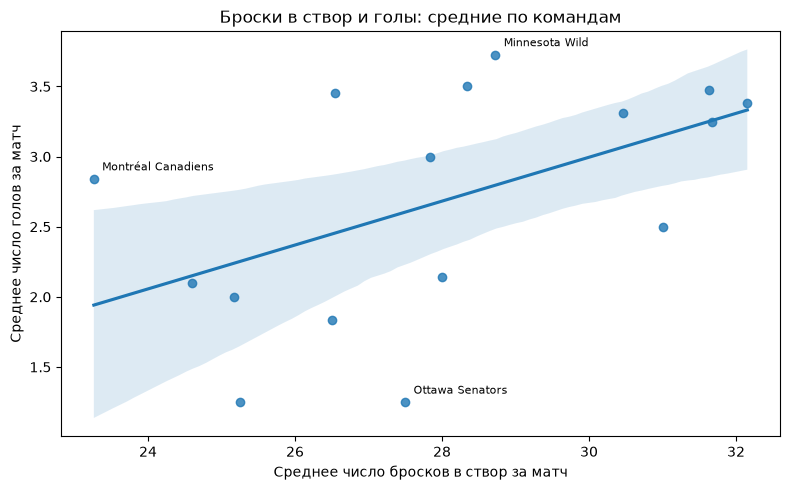

In [15]:
plt.figure(figsize=(8, 5))
reg_ax = sns.regplot(data=avgshots, x="Shot", y="Goal", ci=95, seed=0)

for team in ["Montréal Canadiens", "Minnesota Wild", "Ottawa Senators"]:
    plt.annotate(
        team,
        xy=(avgshots.loc[team, "Shot"], avgshots.loc[team, "Goal"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
    )

plt.xlabel("Среднее число бросков в створ за матч")
plt.ylabel("Среднее число голов за матч")
plt.title("Броски в створ и голы: средние по командам")
plt.tight_layout()
plt.show()

Связь положительная, но разброс большой. По 16 командным средним нельзя установить причинность.

## 14. Где было больше всего бросков

Сюда включаем и заблокированные броски.

In [16]:
all_shot_types = ["goal", "shot-on-goal", "missed-shot", "blocked-shot"]
all_shots = events.loc[events["Play Type"].isin(all_shot_types)].copy()
shots_per_game = all_shots.groupby("Game ID").size()

idxmax = shots_per_game.idxmax()
max_shot_count = shots_per_game.loc[idxmax]
max_shot_ids = shots_per_game.index[shots_per_game == max_shot_count]

for gameId in max_shot_ids:
    print(gameInfo(gameId))
    print("Число бросков:", max_shot_count)

display(all_shots.loc[all_shots["Game ID"] == idxmax, "Play Type"].value_counts())
print("Все броски в данных:", len(all_shots))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Число бросков: 208


Play Type
shot-on-goal    83
missed-shot     66
blocked-shot    54
goal             5
Name: count, dtype: int64

Все броски в данных: 10064


Максимум - **208** попыток в матче Carolina - Ottawa `2025030132`.

## 15. Карта бросков

В нечётных периодах меняем знак обеих координат, сохраняя исходные.

Функция площадки взята из выданного `rink.py` и включена ниже.

In [17]:
# Функция площадки из rink.py
def plot_rink(annotations=False):
    plt.gcf().gca().add_artist(plt.Rectangle((-103,-44.5), 206, 89,
                                             linewidth=0,
                                             facecolor='whitesmoke',
                                             zorder=-2))

    line, = plt.plot([0,0], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='firebrick', zorder=-1)
    plt.scatter([0,0,0,0,0,0,0,0,0,0,0,0], [6,12,18,24,30,36,-6,-12,-18,-24,-30,-36], s=3, color='w', zorder=-1)
    for x in [-25, 25]:
        plt.plot([x,x], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='royalblue', zorder=-1)
    for x in [-25-64, 25+64]:
        plt.plot([x,x], [-36.75,36.75], linewidth=1, solid_capstyle='butt', color='firebrick', zorder=-1)

    plt.gcf().gca().add_artist(plt.Circle((0,0), 15, fill=False,
                                          linewidth=1, color='royalblue', zorder=-1))
    for x in [69, -69]:
        for y in [22, -22]:
            plt.gcf().gca().add_artist(plt.Circle((x,y), 15, fill=False,
                                                  linewidth=1, color='firebrick', zorder=-1))
            for dx in [-1,1]:
                for dy in [-1,1]:
                    plt.plot([x+dx*3,x+dx*1,x+dx*1], [y+dy*0.5,y+dy*0.5,y+dy*2], linewidth=1, color='firebrick', zorder=-1)
                    plt.plot([x+dx*1.5,x+dx*1.5], [y+dy*14.93,y+dy*16], linewidth=1, color='firebrick', zorder=-1)

    plt.scatter([0], [0], s=4, color='royalblue', zorder=-1)
    plt.scatter([69,69,-69,-69,-20,-20,20,20], [22,-22,22,-22,22,-22,22,-22], s=6, color='firebrick', zorder=-1)

    plt.gcf().gca().add_artist(mpatches.Arc((0,-42.5), 10, 10, angle=0, theta1=0, theta2=180,
                                            color='firebrick', zorder=-1))

    for xscale,thoffset in [(-1,0), (1,180)]:
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [-4,-4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [4,4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [-4,-3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [4,3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.gcf().gca().add_artist(mpatches.Arc((xscale*(25+64),0), 12, 12,
                                                angle=0, theta1=-41.75+thoffset, theta2=41.75+thoffset,
                                                color='firebrick', zorder=-1))
        plt.plot([xscale*(25+64),xscale*(25+64+10/3),xscale*(25+64+10/3),xscale*(25+64)], [-3,-3,3,3], linewidth=1, color='firebrick', zorder=-1)

    for dx in [-1,1]:
        for dy in [-1,1]:
            plt.plot([dx*(25+64),dx*(100)], [dy*11,dy*14], linewidth=1, color='firebrick', zorder=-1)

    plt.plot([-100+28,100-28], [42.5,42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100+28,100-28], [-42.5,-42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100,-100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    plt.plot([100,100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)

    plt.gcf().gca().add_artist(mpatches.Arc((100-28,42.5-28), 2*28, 2*28, angle=0, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,42.5-28), 2*28, 2*28, angle=90, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,-42.5+28), 2*28, 2*28, angle=180, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,-42.5+28), 2*28, 2*28, angle=-90, theta1=0, theta2=90,
                                            color='black', zorder=-1))

    if annotations:

        plt.annotate("$0{,}0$", (2,2), ha='left', va='top')
        plt.annotate("${-}20{,}22$", (-18,24), ha='left', va='top')
        plt.annotate("$69{,}{-}22$", (69,-24), ha='center', va='top')
        plt.annotate("$89{,}0$", (87,0), ha='right', va='center')
        plt.annotate("${-}89{,}0$", (-87,0), ha='left', va='center')

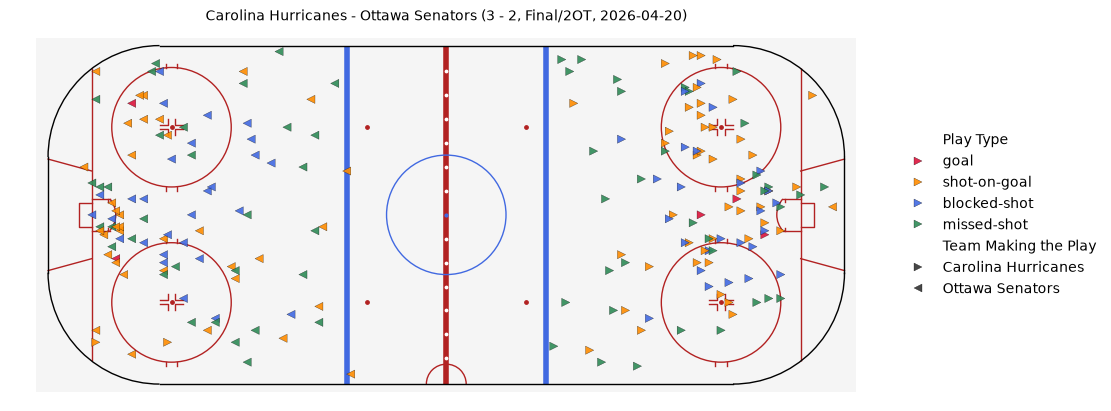

In [18]:
# Отдельные координаты для графика
game_shots = all_shots.loc[all_shots["Game ID"] == idxmax].copy()
game_shots["Plot X"] = game_shots["X Coordinate on the Ice Rink"]
game_shots["Plot Y"] = game_shots["Y Coordinate on the Ice Rink"]
odd_period = game_shots["Period"] % 2 == 1
game_shots.loc[odd_period, ["Plot X", "Plot Y"]] = -game_shots.loc[
    odd_period, ["Plot X", "Plot Y"]
]

home_team = games.loc[idxmax, "Home Team"]
away_team = games.loc[idxmax, "Away Team"]

plt.figure(figsize=(11, 4))
plot_rink()
rink_ax = sns.scatterplot(
    data=game_shots,
    x="Plot X",
    y="Plot Y",
    hue="Play Type",
    hue_order=["goal", "shot-on-goal", "blocked-shot", "missed-shot"],
    palette={
        "goal": "crimson",
        "shot-on-goal": "darkorange",
        "blocked-shot": "royalblue",
        "missed-shot": "seagreen",
    },
    style="Team Making the Play",
    style_order=[home_team, away_team],
    markers={home_team: ">", away_team: "<"},
    s=35,
    alpha=0.9,
    edgecolor="black",
    linewidth=0.2,
)
rink_ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.axis("equal")
plt.axis("off")
plt.title(gameInfo(idxmax), fontsize=10)
plt.tight_layout(pad=0.3)
plt.show()

208 попыток: 109 у Carolina, 99 у Ottawa. Цвет - исход, значок - команда. Хозяева атакуют вправо, гости - влево; точки местами перекрываются.

## 16. Лидеры по голам

При равенстве голов сортируем по имени.

In [19]:
scorers = events.loc[
    events["Play Type"] == "goal", "Player in the Event #1"
]
goals_by_player = (
    scorers.value_counts()
    .reset_index(name="Goals")
    .rename(columns={"Player in the Event #1": "Player"})
)

goals_by_player = goals_by_player.sort_values(
    ["Goals", "Player"], ascending=[False, True]
)
top10_goals = goals_by_player.head(10)
display(top10_goals)

,Player,Goals
0,Brett Howden,14
1,Pavel Dorofeyev,12
2,Logan Stankoven,11
3,Mitch Marner,10
5,Jordan Staal,8
4,Nikolaj Ehlers,8
8,Alex Newhook,7
10,Jackson Blake,7
11,Mark Stone,7
9,Matt Boldy,7


Brett Howden - 14 голов. У шести игроков по 7, поэтому состав десятки зависит от порядка при равенстве.

## 17. Лидеры по передачам

Объединяем поля ассистентов №2 и №3 у голов.

In [20]:
goal_assists = events.loc[
    events["Play Type"] == "goal",
    ["Player in the Event #2", "Player in the Event #3"],
]
assist_players = pd.concat(
    [goal_assists["Player in the Event #2"],
     goal_assists["Player in the Event #3"]],
    ignore_index=True,
).dropna()

assists_by_player = (
    assist_players.value_counts()
    .rename_axis("Player")
    .reset_index(name="Assists")
)

assists_by_player = assists_by_player.sort_values(
    ["Assists", "Player"], ascending=[False, True]
)
top10_assists = assists_by_player.head(10)
display(top10_assists)
print("Всего передач:", assists_by_player["Assists"].sum())

,Player,Assists
0,Jack Eichel,20
1,Mitch Marner,19
2,Jackson Blake,13
3,Lane Hutson,13
7,Martin Necas,12
6,Nick Suzuki,12
4,Shea Theodore,12
5,Taylor Hall,12
8,Kirill Kaprizov,11
9,Quinn Hughes,11


Всего передач: 830


Jack Eichel - 20 передач, Mitch Marner - 19. Всего передач 830.

## 18. Гол плюс пас

Берём полные списки голов и передач, а не только десятки.

In [21]:
point_players = pd.concat(
    [scorers, assist_players], ignore_index=True
).dropna()
points_by_player = (
    point_players.value_counts()
    .rename_axis("Player")
    .reset_index(name="Points")
)

points_by_player = points_by_player.sort_values(
    ["Points", "Player"], ascending=[False, True]
)
top10_points = points_by_player.head(10)
display(top10_points)
print("Всего очков:", points_by_player["Points"].sum())

,Player,Points
0,Mitch Marner,29
1,Jack Eichel,22
2,Jackson Blake,20
3,Taylor Hall,19
6,Brett Howden,18
4,Nikolaj Ehlers,18
5,Shea Theodore,18
9,Lane Hutson,16
8,Logan Stankoven,16
7,Nick Suzuki,16


Всего очков: 1316


Mitch Marner - 29 очков. Всего 1316; равные результаты упорядочены по имени.

## 19. Броски в створ за сыгранный матч

Делим на все матчи участия по составам, включая матчи без бросков в створ.

In [22]:
# Считаю каждый матч один раз
player_game_counts = {}
for gameId, game_events in events.groupby("Game ID"):
    game_players = set()
    for column in player_columns:
        game_players.update(game_events[column].dropna())
    for player in game_players:
        player_game_counts[player] = player_game_counts.get(player, 0) + 1

games_by_player = pd.Series(player_game_counts, name="Games", dtype="int64")
player_shots = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal"]),
    "Player in the Event #1",
].value_counts()

player_shot_stats = pd.DataFrame({"Shots": player_shots, "Games": games_by_player})
player_shot_stats["Shots"] = player_shot_stats["Shots"].fillna(0).astype(int)
player_shot_stats["Shots per Game"] = (
    player_shot_stats["Shots"] / player_shot_stats["Games"]
)
player_shot_stats = player_shot_stats.rename_axis("Player").reset_index()
player_shot_stats = player_shot_stats.sort_values(
    ["Shots per Game", "Player"], ascending=[False, True]
)
top10_player_shots = player_shot_stats.head(10)

display(top10_player_shots.round(3))

,Player,Shots,Games,Shots per Game
155,Jason Robertson,30,6,5.000
100,Dylan Guenther,27,6,4.500
268,Nikita Kucherov,31,7,4.429
231,Matt Boldy,48,11,4.364
295,Quinton Byfield,17,4,4.250
88,Darren Raddysh,28,7,4.000
167,Joel Eriksson Ek,24,6,4.000
5,Alex Laferriere,15,4,3.750
89,David Pastrnak,22,6,3.667
255,Nathan MacKinnon,47,13,3.615


Jason Robertson - 30/6 = 5. У Pastrnak броски в створ были в пяти матчах, но сыграл он шесть: 22/6. Отдельного протокола выходов нет.

## 20. Силовые приёмы за матч

Матчи без приёмов тоже входят в знаменатель.

In [23]:
player_hits = events.loc[
    events["Play Type"] == "hit", "Player in the Event #1"
].value_counts()

player_hit_stats = pd.DataFrame({"Hits": player_hits, "Games": games_by_player})
player_hit_stats["Hits"] = player_hit_stats["Hits"].fillna(0).astype(int)
player_hit_stats["Hits per Game"] = (
    player_hit_stats["Hits"] / player_hit_stats["Games"]
)
player_hit_stats = player_hit_stats.rename_axis("Player").reset_index()
player_hit_stats = player_hit_stats.sort_values(
    ["Hits per Game", "Player"], ascending=[False, True]
)
top10_player_hits = player_hit_stats.head(10)
display(top10_player_hits.round(3))

,Player,Hits,Games,Hits per Game
204,Lawson Crouse,38,6,6.333
10,Alex Turcotte,6,1,6.000
13,Alexander Petrovic,6,1,6.000
364,Yakov Trenin,51,9,5.667
99,Dylan Cozens,22,4,5.500
356,Vasily Podkolzin,32,6,5.333
58,Carl Grundstrom,15,3,5.000
125,Ivan Barbashev,110,22,5.000
221,Marcus Foligno,55,11,5.000
285,Owen Tippett,29,6,4.833


Lawson Crouse - 38/6 ≈ 6,333. Минимум сыгранных матчей условием не задан.

## 21. Вратари без пропущенных за своё участие

У 22 голов в OT состав пустой. В пяти случаях имя вратаря меняется прямо в строке гола. Неясно, на какой момент записан состав; пропуск не считаем нулём.

Сравниваем текущую строку и, как гипотезу, предыдущую строку того же матча. Пустые ворота предполагаем при пустом поле вратаря и шести разных полевых без известных вратарей. Остальные пропуски неизвестны; отдельного флага пустых ворот нет.

In [24]:
def goalie_game_stats(events, use_previous=False):
    goalie_names = set(pd.concat([
        events["Away Team's Goalie"], events["Home Team's Goalie"]
    ]).dropna())
    records = []
    for gameId, game_events in events.groupby("Game ID"):
        for side, opponent in [("Away", "Home"), ("Home", "Away")]:
            column = f"{side} Team's Goalie"
            roster_columns = [f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)]
            played_goalies = game_events[column].dropna().unique()
            opposing_goals = (
                (game_events["Play Type"] == "goal")
                & (game_events["Team Making the Play"]
                   == game_events[f"{opponent} Team"])
            )

            goalie_at_event = game_events[column]
            roster_at_event = game_events[roster_columns]
            if use_previous:

                # Предыдущая строка в этом матче
                goalie_at_event = goalie_at_event.shift(1)
                roster_at_event = roster_at_event.shift(1)

            # Проверка пустых ворот
            six_skaters = (
                roster_at_event.notna().all(axis=1)
                & (roster_at_event.nunique(axis=1) == 6)
                & ~roster_at_event.isin(goalie_names).any(axis=1)
            )
            empty_net = goalie_at_event.isna() & six_skaters

            goalies_on_goals = goalie_at_event.loc[opposing_goals]
            conceded = goalies_on_goals.value_counts()
            empty_net_goals = int(empty_net.loc[opposing_goals].sum())
            unknown = int(
                (goalies_on_goals.isna() & ~empty_net.loc[opposing_goals]).sum()
            )

            for goalie in played_goalies:
                records.append({
                    "Game ID": gameId,
                    "Team": game_events[f"{side} Team"].iloc[0],
                    "Goalie": goalie,
                    "Goals Against": int(conceded.get(goalie, 0)),
                    "Empty Net Team Goals": empty_net_goals,
                    "Unknown Team Goals": unknown,
                })

    return pd.DataFrame(records, columns=[
        "Game ID", "Team", "Goalie", "Goals Against",
        "Empty Net Team Goals", "Unknown Team Goals"
    ])

def supported_zero_goalies(stats):

    zero = (stats["Goals Against"] == 0) & (stats["Unknown Team Goals"] == 0)
    return set(stats.loc[zero, "Goalie"])

goalie_stats_current = goalie_game_stats(events)
goalie_stats_previous = goalie_game_stats(events, use_previous=True)
current_zero_goalies = supported_zero_goalies(goalie_stats_current)
previous_zero_goalies = supported_zero_goalies(goalie_stats_previous)
confirmed_goalies = sorted(current_zero_goalies & previous_zero_goalies)

uncertain_goalie_games = goalie_stats_current.loc[
    (goalie_stats_current["Goals Against"] == 0)
    & (goalie_stats_current["Unknown Team Goals"] > 0)
].copy()

In [25]:
balance_rows = []
for label, stats in [("Текущая строка", goalie_stats_current),
                     ("Предыдущая строка", goalie_stats_previous)]:
    team_games = stats.drop_duplicates(["Game ID", "Team"])
    balance_rows.append([
        label,
        stats["Goals Against"].sum(),
        team_games["Empty Net Team Goals"].sum(),
        team_games["Unknown Team Goals"].sum(),
    ])
display(pd.DataFrame(balance_rows, columns=[
    "Вариант", "Назначены вратарю", "Пустые ворота", "Неизвестно"
]))
print("Совпадает в обоих вариантах; полнота списка не установлена:")
display(pd.DataFrame({"Goalie": confirmed_goalies}))
print("Если использовать предыдущий состав (это гипотеза):")
display(pd.DataFrame({"Goalie": sorted(previous_zero_goalies)}))
print("Эти нули по текущей строке не подтверждены из-за пропусков:")
display(uncertain_goalie_games)

,Вариант,Назначены вратарю,Пустые ворота,Неизвестно
0,Текущая строка,461,3,22
1,Предыдущая строка,452,33,1


Совпадает в обоих вариантах; полнота списка не установлена:


,Goalie
0,Andrei Vasilevskiy
1,Brandon Bussi
2,Dan Vladar
3,Frederik Andersen
4,Joonas Korpisalo
5,Scott Wedgewood


Если использовать предыдущий состав (это гипотеза):


,Goalie
0,Alex Lyon
1,Andrei Vasilevskiy
2,Brandon Bussi
3,Dan Vladar
4,Frederik Andersen
5,Joonas Korpisalo
6,Scott Wedgewood
7,Ukko-Pekka Luukkonen


Эти нули по текущей строке не подтверждены из-за пропусков:


,Game ID,Team,Goalie,Goals Against,Empty Net Team Goals,Unknown Team Goals
25,2025030126,Montréal Canadiens,Jakub Dobes,0,0,1
46,2025030146,Pittsburgh Penguins,Arturs Silovs,0,0,1
166,2025030413,Carolina Hurricanes,Brandon Bussi,0,0,1


В обоих вариантах шесть имён; по предыдущему составу добавляются Alex Lyon и Ukko-Pekka Luukkonen. **Полный список не установлен:** совпадение двух вариантов не доказывает их правильность. Подробности - в `report.txt`.

## 22. Свой вопрос

**Кто выиграл больше всего OT-матчей и какова доля побед каждой команды в таких матчах?**

In [26]:
overtime_games = games.loc[games["Outcome"] != "Final"]
overtime_rows = []
for gameId, game in overtime_games.iterrows():
    if game["Away Score"] == game["Home Score"]:
        raise ValueError(f"Ничейный итоговый счёт в матче {gameId}")
    away_won = game["Away Score"] > game["Home Score"]
    overtime_rows.append([game["Away Team"], int(away_won)])
    overtime_rows.append([game["Home Team"], int(not away_won)])

overtime_stats = (
    pd.DataFrame(overtime_rows, columns=["Team", "Win"])
    .groupby("Team")["Win"]
    .agg(["count", "sum"])
    .rename(columns={"count": "OT Games", "sum": "OT Wins"})
)
overtime_stats["OT Losses"] = overtime_stats["OT Games"] - overtime_stats["OT Wins"]
overtime_stats["Win %"] = 100 * overtime_stats["OT Wins"] / overtime_stats["OT Games"]
overtime_stats = overtime_stats.reset_index().sort_values(
    ["OT Wins", "Team"], ascending=[False, True]
)

if overtime_stats.empty:
    print("Матчей с овертаймом нет.")
else:
    display(overtime_stats.round({"Win %": 1}))

,Team,OT Games,OT Wins,OT Losses,Win %
3,Carolina Hurricanes,7,6,1,85.7
15,Vegas Golden Knights,5,4,1,80.0
9,Montréal Canadiens,7,3,4,42.9
4,Colorado Avalanche,2,2,0,100.0
13,Tampa Bay Lightning,4,2,2,50.0
0,Anaheim Ducks,2,1,1,50.0
1,Boston Bruins,1,1,0,100.0
5,Dallas Stars,2,1,1,50.0
8,Minnesota Wild,3,1,2,33.3
11,Philadelphia Flyers,3,1,2,33.3


Лидер - **Carolina: 6 из 7, 85,7%**. У Boston и Colorado по 100%, но только один и два матча. Всего OT-матчей 22; двойной OT - одна игра. Малой выборки недостаточно для вывода об устойчивой силе команд.

### Короткая проверка сумм

Проверяем основные числа для этого Excel.

In [27]:
assert input_shape == (29710, 38)
assert len(games) == 82
assert games["Total Score"].sum() == 486
assert len(shots) == 7266
assert shots["On Goal"].sum() == 4623
assert len(all_shots) == 10064
assert max_shot_count == 208
assert max_player_count == 40
assert assists_by_player["Assists"].sum() == 830
assert points_by_player["Points"].sum() == 1316
assert player_hit_stats["Hits"].sum() == 5621
assert len(confirmed_goalies) == 6
assert len(previous_zero_goalies) == 8
assert len(overtime_games) == 22
assert overtime_stats["OT Games"].sum() == 44
assert overtime_stats["OT Wins"].sum() == 22
print("Контрольные суммы сошлись.")

Контрольные суммы сошлись.


Подробные проверки и ограничения - в `report.txt`.